In [1]:
# import openai
import os

import json
import argparse
import tqdm
import time
import textstat

import re
import pickle

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import prettytable
from prettytable import PrettyTable
from scipy.stats import spearmanr, pearsonr, kendalltau
import torch
from transformers import GPT2Tokenizer, GPT2LMHeadModel
import math

/users/faculty/sadeghi/.conda/envs/torchenv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2025-07-29 15:48:11.906829: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1753814891.919266 1870388 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1753814891.923064 1870388 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1753814891.933082 1870388 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target 

In [13]:
summeval_fp = '/users/data/summeval.json'
prompt_fp1 = '/users/prompts/summeval/coh_detailed.txt'
prompt_fp1 = '/users/prompts/summeval/rel_detailed.txt'
save_fp = '/users/results/gpt4_con_detailed_openai.json'

input_fp_rel = '/users/results/gpt4_rel_detailed.json'
input_fp_coh = '/users/results/gpt4_coh_detailed.json'

saving_path = '/users/results/figures'

In [14]:
def compute_entropy_from_loss(text, model_name="gpt2"):
    tokenizer = GPT2Tokenizer.from_pretrained(model_name)
    model = GPT2LMHeadModel.from_pretrained(model_name)
    model.eval()

    # Encode input
    inputs = tokenizer(text, return_tensors="pt")
    input_ids = inputs["input_ids"]

    with torch.no_grad():
        outputs = model(input_ids, labels=input_ids)
        loss = outputs.loss  # average negative log likelihood (in nats)

    # Convert from natural log to bits (Shannon entropy)
    entropy_bits = loss.item() / math.log(2)

    return entropy_bits


In [15]:
with open(input_fp_rel, 'r', encoding='utf-8') as f:
        jobj = json.load(f)

In [17]:
def measure_all_entropy(input_fp, dimension='relevance'):
    ''' measure linguistic complexity '''
    with open(input_fp, 'r', encoding='utf-8') as f:
        jobj = json.load(f)

    model_scores, human_scores, entropy_scores = {}, {}, {}

    for idx,item in enumerate(jobj):
        # print(f"item: {idx} ")
        doc_id = item["doc_id"]
        # print(doc_id)
        if doc_id not in model_scores:  
            model_scores[doc_id] = []
            human_scores[doc_id] = []
            entropy_scores[doc_id] = []

        # Model score
        all_responses = item["all_responses"]
        all_scores = [parse_output(x) for x in all_responses]
        score = sum(all_scores) / len(all_scores)

        model_scores[doc_id].append(score)
        human_scores[doc_id].append(item['scores'][dimension])

        # entropy measurement
        paragraph = item.get("system_output", "").strip()
        if paragraph:
            # print('ent')
            text_entropy = compute_entropy_from_loss(paragraph, model_name="gpt2")
            entropy_scores[doc_id].append(text_entropy)

    return model_scores, human_scores, entropy_scores

In [18]:
def parse_output(output):
    matched = re.search("^ ?([\d\.]+)", output)
    if (matched):
        try:
            score = float(matched.group(1))
        except:
            score = 0
    else:
        score = 0
    return score

<>:2: SyntaxWarning: invalid escape sequence '\d'
<>:2: SyntaxWarning: invalid escape sequence '\d'
/tmp/ipykernel_1870388/2072338213.py:2: SyntaxWarning: invalid escape sequence '\d'
  matched = re.search("^ ?([\d\.]+)", output)


In [19]:
# ------------------Compute entropies--------------------
# model_scores_rel,human_scores_rel, ent_scores_rel = measure_all_entropy(input_fp_rel, dimension = 'relevance')
# model_scores_coh,human_scores_coh, ent_scores_coh = measure_all_entropy(input_fp_coh, dimension = 'coherence')
# model_scores_flu,human_scores_flu, ent_scores_flu = measure_all_entropy(input_fp_flu, dimension = 'fluency')
# model_scores_con,human_scores_con, ent_scores_con = measure_all_entropy(input_fp_con, dimension = 'consistency')


# save_dir = '/users/faculty/sadeghi/exps/botval/results'
# file_path = os.path.join(save_dir, 'dicts_ent_scores_rel.pkl')
# rel_dicts = [model_scores_rel, human_scores_rel, ent_scores_rel]

# with open(file_path, 'wb') as f:
#     pickle.dump(rel_dicts, f)

# file_path = os.path.join(save_dir, 'dicts_ent_scores_coh.pkl')
# rel_dicts = [model_scores_rel, human_scores_rel, ent_scores_rel]

# with open(file_path, 'wb') as f:
#     pickle.dump(rel_dicts, f)

# file_path = os.path.join(save_dir, 'dicts_ent_scores_flu.pkl')
# rel_dicts = [model_scores_flu, human_scores_flu, ent_scores_flu]

# with open(file_path, 'wb') as f:
#     pickle.dump(rel_dicts, f)

# file_path = os.path.join(save_dir, 'dicts_ent_scores_con.pkl')
# rel_dicts = [model_scores_con, human_scores_con, ent_scores_con]

# with open(file_path, 'wb') as f:
#     pickle.dump(rel_dicts, f)

In [20]:
# Load all the entropy results -- relevance
save_dir = '/users/faculty/sadeghi/exps/botval/results'
file_path = os.path.join(save_dir, 'output_dicts_ent_scores_rel.pkl')
with open(file_path, 'rb') as file:
    m_scores_rel,h_scores_rel,e_scores_rel = pickle.load(file)


In [21]:
# Load all the entropy results -- coherence
save_dir = '/users/faculty/sadeghi/exps/botval/results'
file_path = os.path.join(save_dir, 'output_dicts_ent_scores_coh.pkl')
with open(file_path, 'rb') as file:
    m_scores_coh,h_scores_coh,e_scores_coh = pickle.load(file)


In [22]:
# Load all the entropy results -- consistency
save_dir = '/users/faculty/sadeghi/exps/botval/results'
file_path = os.path.join(save_dir, 'output_dicts_ent_scores_con.pkl')
with open(file_path, 'rb') as file:
    m_scores_con,h_scores_con,e_scores_con = pickle.load(file)


In [23]:
# Load all the entropy results -- fluency
save_dir = '/users/faculty/sadeghi/exps/botval/results'
file_path = os.path.join(save_dir, 'output_dicts_ent_scores_flu.pkl')
with open(file_path, 'rb') as file:
    m_scores_flu,h_scores_flu,e_scores_flu = pickle.load(file)


In [24]:
# e_scores_flu

In [25]:
def rescale_dict(data, new_min=1, new_max=5):
    # Flatten all values to find global min and max
    all_values = [val for sublist in data.values() for val in sublist]
    old_min = min(all_values)
    old_max = max(all_values)

    # Avoid division by zero
    if old_max == old_min:
        return {key: [new_min for _ in vals] for key, vals in data.items()}

    # Rescale function
    def rescale(x):
        return ((x - old_min) / (old_max - old_min)) * (new_max - new_min) + new_min

    # Apply rescaling
    return {key: [rescale(x) for x in vals] for key, vals in data.items()}



In [24]:
e_scores_rel_stand = rescale_dict(e_scores_rel, new_min=1, new_max=5)
e_scores_con_stand = rescale_dict(e_scores_con, new_min=1, new_max=5)
e_scores_coh_stand = rescale_dict(e_scores_coh, new_min=1, new_max=5)
e_scores_flu_stand = rescale_dict(e_scores_flu, new_min=1, new_max=5)

/tmp/ipykernel_1326504/2756317718.py:2: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(e_scores_con_stand.values(), labels=e_scores_con_stand.keys())


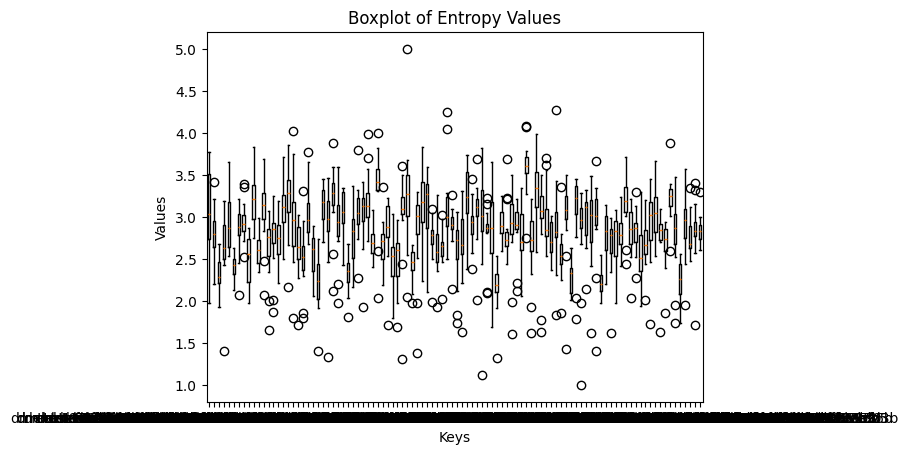

In [15]:
# Create boxplot
plt.boxplot(e_scores_con_stand.values(), labels=e_scores_con_stand.keys())

# Add title and labels
plt.title("Boxplot of Entropy Values")
plt.xlabel("Keys")
plt.ylabel("Values")

# Show plot
plt.show()

/tmp/ipykernel_1303472/1221321.py:2: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(e_scores_con.values(), labels=e_scores_con.keys())


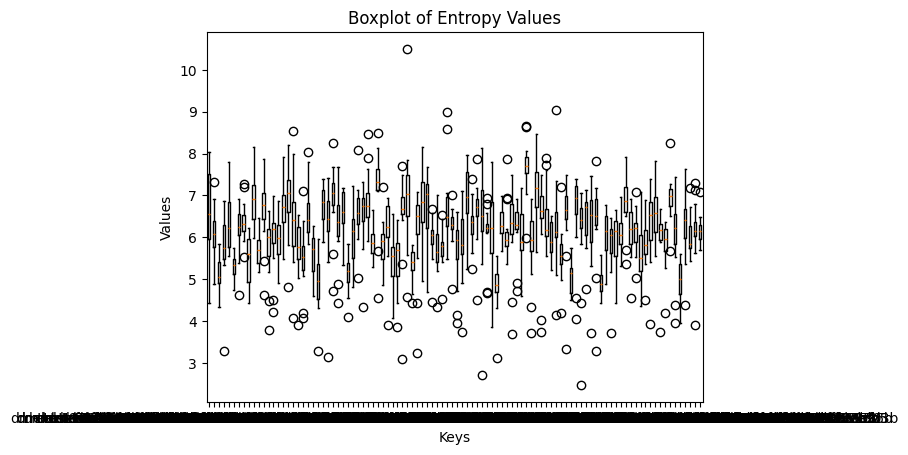

In [14]:
# Create boxplot
plt.boxplot(e_scores_con.values(), labels=e_scores_con.keys())

# Add title and labels
plt.title("Boxplot of Entropy Values")
plt.xlabel("Keys")
plt.ylabel("Values")

# Show plot
plt.show()

In [11]:
e_scores_con_avg = {key: sum(values) / len(values) for key, values in e_scores_con.items()}

In [24]:
# e_scores_con_avg

In [16]:
all_ent_values = [value for values in e_scores_con_stand.values() for value in values]

In [17]:
sorted_ents = sorted(all_ent_values)

In [18]:
all_values = sorted_ents

min_val = min(all_values)
max_val = max(all_values)

# Define thresholds
range_size = (max_val - min_val) / 3
low_thresh = min_val + range_size
high_thresh = min_val + 2 * range_size

# Cluster the values
low = [x for x in all_values if x < low_thresh]
medium = [x for x in all_values if low_thresh <= x < high_thresh]
high = [x for x in all_values if x >= high_thresh]

# print("Low:", low)
# print("Medium:", medium)
# print("High:", high)


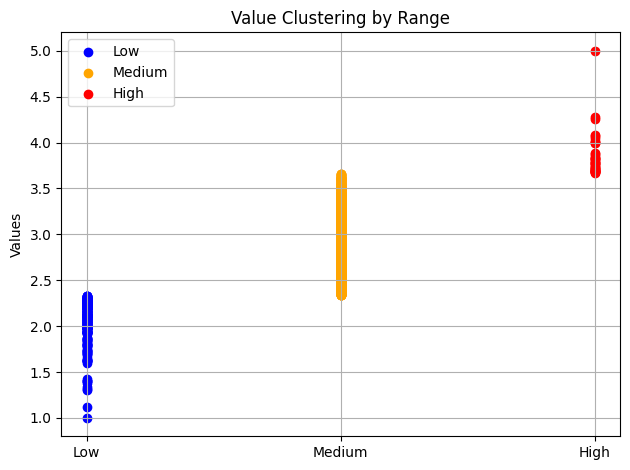

In [19]:
x_low = [1] * len(low)
x_med = [2] * len(medium)
x_high = [3] * len(high)

# Step 4: Plot
plt.scatter(x_low, low, color='blue', label='Low')
plt.scatter(x_med, medium, color='orange', label='Medium')
plt.scatter(x_high, high, color='red', label='High')

plt.xticks([1, 2, 3], ['Low', 'Medium', 'High'])
plt.ylabel("Values")
plt.title("Value Clustering by Range")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.show()



In [45]:
dict1, dict2, dict3  =  h_scores_rel, m_scores_rel, e_scores_rel_stand


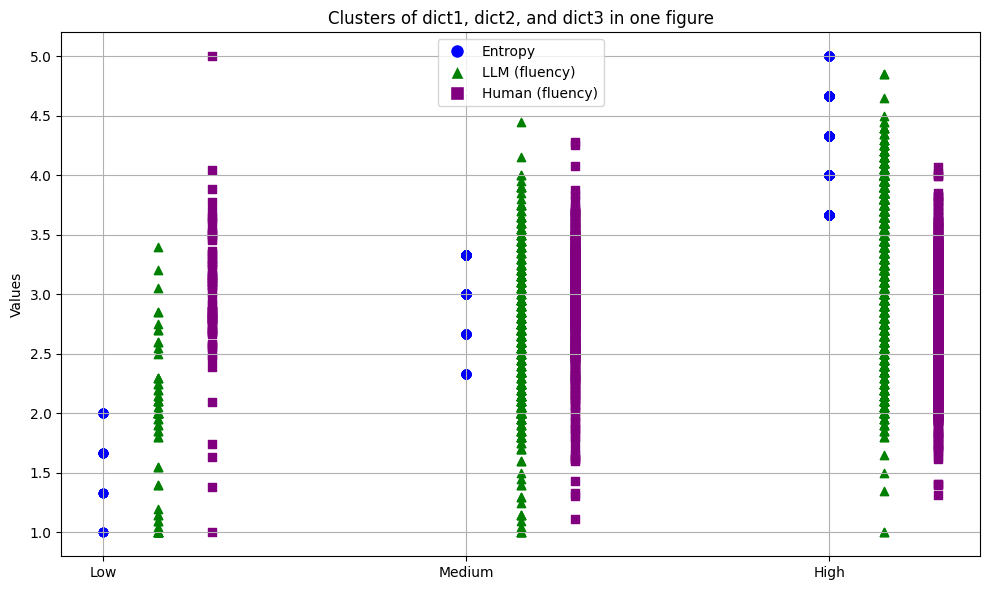

In [46]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D


# Flatten dict1 (key, index, value)
flattened1 = [(k, i, v) for k, lst in dict1.items() for i, v in enumerate(lst)]

# Create lookup dicts for dict2 and dict3
lookup2 = {(k, i): dict2[k][i] for k in dict2 for i in range(len(dict2[k]))}
lookup3 = {(k, i): dict3[k][i] for k in dict3 for i in range(len(dict3[k]))}

# Sort dict1 values by value
flattened1_sorted = sorted(flattened1, key=lambda x: x[2])

# Extract sorted dict1 values and aligned dict2, dict3 values
values1_sorted = [v for (_, _, v) in flattened1_sorted]
values2_aligned = [lookup2[(k, i)] for (k, i, _) in flattened1_sorted]
values3_aligned = [lookup3[(k, i)] for (k, i, _) in flattened1_sorted]

# Compute clustering thresholds based on dict1 values
min_val = min(values1_sorted)
max_val = max(values1_sorted)
range_size = (max_val - min_val) / 3
low_thresh = min_val + range_size
high_thresh = min_val + 2 * range_size

# Cluster dict1 values
low1 = [v for v in values1_sorted if v < low_thresh]
med1 = [v for v in values1_sorted if low_thresh <= v < high_thresh]
high1 = [v for v in values1_sorted if v >= high_thresh]

# Cluster dict2 values using dict1’s clustering
low2 = [v2 for v1, v2 in zip(values1_sorted, values2_aligned) if v1 < low_thresh]
med2 = [v2 for v1, v2 in zip(values1_sorted, values2_aligned) if low_thresh <= v1 < high_thresh]
high2 = [v2 for v1, v2 in zip(values1_sorted, values2_aligned) if v1 >= high_thresh]

# Cluster dict3 values using dict1’s clustering
low3 = [v3 for v1, v3 in zip(values1_sorted, values3_aligned) if v1 < low_thresh]
med3 = [v3 for v1, v3 in zip(values1_sorted, values3_aligned) if low_thresh <= v1 < high_thresh]
high3 = [v3 for v1, v3 in zip(values1_sorted, values3_aligned) if v1 >= high_thresh]

# X positions for clusters, slightly offset for each dict for clarity
x_low_1 = [1] * len(low1)
x_med_1 = [2] * len(med1)
x_high_1 = [3] * len(high1)

x_low_2 = [1.15] * len(low2)
x_med_2 = [2.15] * len(med2)
x_high_2 = [3.15] * len(high2)

x_low_3 = [1.3] * len(low3)
x_med_3 = [2.3] * len(med3)
x_high_3 = [3.3] * len(high3)

plt.figure(figsize=(10,6))

# Use distinct colors per dict
color1 = 'blue'
color2 = 'green'
color3 = 'purple'

# Plot dict1 clusters (circles) with one color
plt.scatter(x_low_1, low1, color=color1, marker='o')
plt.scatter(x_med_1, med1, color=color1, marker='o')
plt.scatter(x_high_1, high1, color=color1, marker='o')

# Plot dict2 clusters (triangles) with one color
plt.scatter(x_low_2, low2, color=color2, marker='^')
plt.scatter(x_med_2, med2, color=color2, marker='^')
plt.scatter(x_high_2, high2, color=color2, marker='^')

# Plot dict3 clusters (squares) with one color
plt.scatter(x_low_3, low3, color=color3, marker='s')
plt.scatter(x_med_3, med3, color=color3, marker='s')
plt.scatter(x_high_3, high3, color=color3, marker='s')

# Custom legend with one color + marker per dict
from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0], [0], marker='o', color='w', label='Entropy', markerfacecolor=color1, markersize=10),
    Line2D([0], [0], marker='^', color='w', label='LLM (fluency)', markerfacecolor=color2, markersize=10),
    Line2D([0], [0], marker='s', color='w', label='Human (fluency)', markerfacecolor=color3, markersize=10),
]

plt.xticks([1, 2, 3], ['Low', 'Medium', 'High'])
plt.ylabel('Values')
plt.title('Clusters of dict1, dict2, and dict3 in one figure')
plt.legend(handles=legend_elements, loc='best')
plt.grid(True)
plt.tight_layout()
plt.show()

In [47]:
len(x1),len(x2),len(x3)

(9, 9, 9)

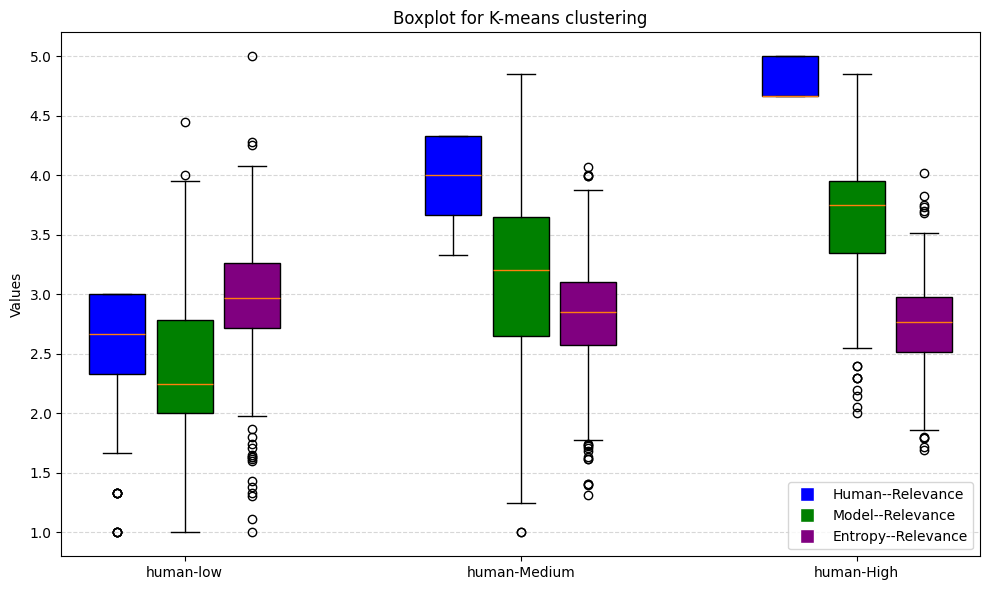

In [55]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from sklearn.cluster import KMeans
import numpy as np
from collections import defaultdict

dict1, dict2, dict3  =  h_scores_rel, m_scores_rel, e_scores_rel_stand


# ---- Step 1: Flatten dict1 ----
flattened1 = [(k, i, v) for k, lst in dict1.items() for i, v in enumerate(lst)]

# ---- Step 2: Create lookup dicts for dict2 and dict3 ----
lookup2 = {(k, i): dict2[k][i] for k in dict2 for i in range(len(dict2[k]))}
lookup3 = {(k, i): dict3[k][i] for k in dict3 for i in range(len(dict3[k]))}

# ---- Step 3: Sort by dict1 values ----
flattened1_sorted = sorted(flattened1, key=lambda x: x[2])
values1_sorted = np.array([v for (_, _, v) in flattened1_sorted]).reshape(-1, 1)
values2_aligned = [lookup2[(k, i)] for (k, i, _) in flattened1_sorted]
values3_aligned = [lookup3[(k, i)] for (k, i, _) in flattened1_sorted]

# ---- Step 4: Apply KMeans clustering to dict1 values ----
k = 3
kmeans = KMeans(n_clusters=k, random_state=0)
clusters = kmeans.fit_predict(values1_sorted)

# ---- Step 5: Sort clusters by center ----
cluster_centers = kmeans.cluster_centers_.flatten()
sorted_clusters = np.argsort(cluster_centers)
cluster_map = {old: new for new, old in enumerate(sorted_clusters)}
mapped_clusters = np.array([cluster_map[c] for c in clusters])

# ---- Step 6: Group values by cluster ----
cluster_values1 = defaultdict(list)
cluster_values2 = defaultdict(list)
cluster_values3 = defaultdict(list)

for idx, cluster_id in enumerate(mapped_clusters):
    cluster_values1[cluster_id].append(values1_sorted[idx][0])
    cluster_values2[cluster_id].append(values2_aligned[idx])
    cluster_values3[cluster_id].append(values3_aligned[idx])

# ---- Step 7: Prepare boxplot data ----
positions = []
data = []
colors = []
labels = []

cluster_spacing = 3  # margin between clusters
group_width = 0.6     # how far apart boxplots are within each cluster
color_map = ['blue', 'green', 'purple']

for cluster_id in sorted(cluster_values1.keys()):
    base_pos = cluster_id * cluster_spacing

    data.append(cluster_values1[cluster_id])
    positions.append(base_pos)
    colors.append(color_map[0])
    labels.append('Dict1' if cluster_id == 0 else "")

    data.append(cluster_values2[cluster_id])
    positions.append(base_pos + group_width)
    colors.append(color_map[1])
    labels.append('Dict2' if cluster_id == 0 else "")

    data.append(cluster_values3[cluster_id])
    positions.append(base_pos + 2 * group_width)
    colors.append(color_map[2])
    labels.append('Dict3' if cluster_id == 0 else "")

# ---- Step 8: Plot boxplots ----
plt.figure(figsize=(10, 6))
box = plt.boxplot(data, positions=positions, widths=0.5, patch_artist=True)

# Set box colors
for patch, color in zip(box['boxes'], colors):
    patch.set_facecolor(color)

# Optional: x-ticks in the center of each cluster group
xticks = [i * cluster_spacing + group_width for i in range(k)]
xtick_labels = ['human-low','human-Medium','human-High']

plt.xticks(xticks, xtick_labels)

# Legend manually added (since boxplot doesn't generate one)
legend_elements = [
    Line2D([0], [0], marker='s', color='w', label='Human--Relevance', markerfacecolor='blue', markersize=10),
    Line2D([0], [0], marker='s', color='w', label='Model--Relevance', markerfacecolor='green', markersize=10),
    Line2D([0], [0], marker='s', color='w', label='Entropy--Relevance', markerfacecolor='purple', markersize=10),
]
plt.legend(handles=legend_elements)

plt.ylabel("Values")
plt.title("Boxplot for K-means clustering")
plt.grid(True, axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


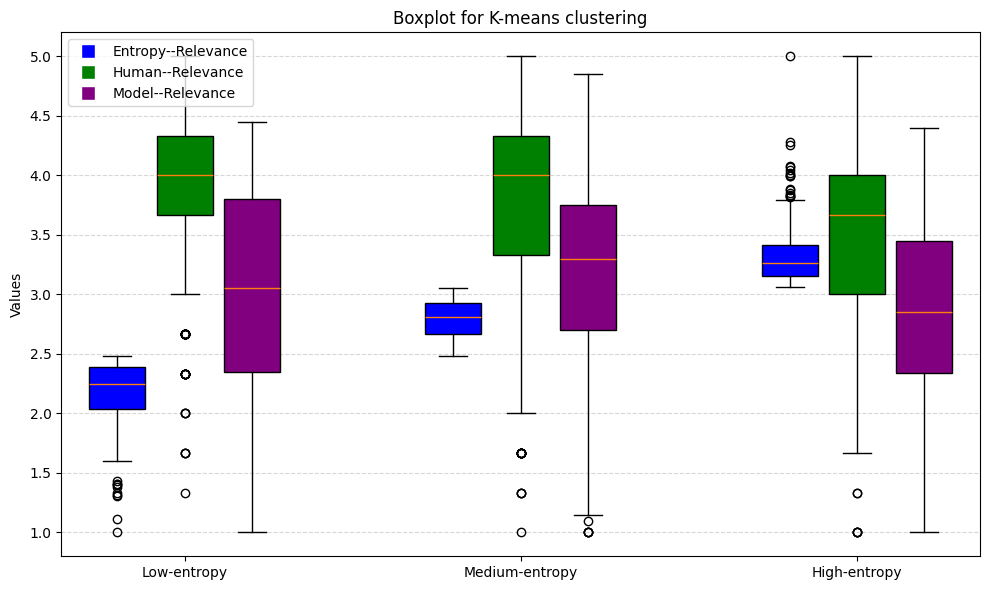

In [74]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from sklearn.cluster import KMeans
import numpy as np
from collections import defaultdict

dict1, dict2, dict3  =   e_scores_rel_stand, h_scores_rel, m_scores_rel


# ---- Step 1: Flatten dict1 ----
flattened1 = [(k, i, v) for k, lst in dict1.items() for i, v in enumerate(lst)]

# ---- Step 2: Create lookup dicts for dict2 and dict3 ----
lookup2 = {(k, i): dict2[k][i] for k in dict2 for i in range(len(dict2[k]))}
lookup3 = {(k, i): dict3[k][i] for k in dict3 for i in range(len(dict3[k]))}

# ---- Step 3: Sort by dict1 values ----
flattened1_sorted = sorted(flattened1, key=lambda x: x[2])
values1_sorted = np.array([v for (_, _, v) in flattened1_sorted]).reshape(-1, 1)
values2_aligned = [lookup2[(k, i)] for (k, i, _) in flattened1_sorted]
values3_aligned = [lookup3[(k, i)] for (k, i, _) in flattened1_sorted]

# ---- Step 4: Apply KMeans clustering to dict1 values ----
k = 3
kmeans = KMeans(n_clusters=k, random_state=0)
clusters = kmeans.fit_predict(values1_sorted)

# ---- Step 5: Sort clusters by center ----
cluster_centers = kmeans.cluster_centers_.flatten()
sorted_clusters = np.argsort(cluster_centers)
cluster_map = {old: new for new, old in enumerate(sorted_clusters)}
mapped_clusters = np.array([cluster_map[c] for c in clusters])

# ---- Step 6: Group values by cluster ----
cluster_values1 = defaultdict(list)
cluster_values2 = defaultdict(list)
cluster_values3 = defaultdict(list)

for idx, cluster_id in enumerate(mapped_clusters):
    cluster_values1[cluster_id].append(values1_sorted[idx][0])
    cluster_values2[cluster_id].append(values2_aligned[idx])
    cluster_values3[cluster_id].append(values3_aligned[idx])

# ---- Step 7: Prepare boxplot data ----
positions = []
data = []
colors = []
labels = []

cluster_spacing = 3  # margin between clusters
group_width = 0.6     # how far apart boxplots are within each cluster
color_map = ['blue', 'green', 'purple']

for cluster_id in sorted(cluster_values1.keys()):
    base_pos = cluster_id * cluster_spacing

    data.append(cluster_values1[cluster_id])
    positions.append(base_pos)
    colors.append(color_map[0])
    labels.append('Dict1' if cluster_id == 0 else "")

    data.append(cluster_values2[cluster_id])
    positions.append(base_pos + group_width)
    colors.append(color_map[1])
    labels.append('Dict2' if cluster_id == 0 else "")

    data.append(cluster_values3[cluster_id])
    positions.append(base_pos + 2 * group_width)
    colors.append(color_map[2])
    labels.append('Dict3' if cluster_id == 0 else "")


# ---- Step 8: Plot boxplots ----
plt.figure(figsize=(10, 6))
box = plt.boxplot(data, positions=positions, widths=0.5, patch_artist=True)


# Set box colors
for patch, color in zip(box['boxes'], colors):
    patch.set_facecolor(color)

# Optional: x-ticks in the center of each cluster group
xticks = [i * cluster_spacing + group_width for i in range(k)]
xtick_labels = ['Low-entropy','Medium-entropy','High-entropy']

plt.xticks(xticks, xtick_labels)

# Legend manually added (since boxplot doesn't generate one)
legend_elements = [
    Line2D([0], [0], marker='s', color='w', label='Entropy--Relevance', markerfacecolor='blue', markersize=10),
    Line2D([0], [0], marker='s', color='w', label='Human--Relevance', markerfacecolor='green', markersize=10),
    Line2D([0], [0], marker='s', color='w', label='Model--Relevance', markerfacecolor='purple', markersize=10),
]

plt.legend(handles=legend_elements)

plt.ylabel("Values")
plt.title("Boxplot for K-means clustering")
plt.grid(True, axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


In [75]:

cluster_r = {}
for cluster_id in sorted(cluster_values1.keys()):
    v1 = np.array(cluster_values1[cluster_id])
    v2 = np.array(cluster_values2[cluster_id])
    v3 = np.array(cluster_values3[cluster_id])
    if len(v1) > 1:
        r12, p12 = pearsonr(v1, v2)
        r13, p13 = pearsonr(v1, v3)
    else:
        r12, p12 = np.nan, 1.0
        r13, p13 = np.nan, 1.0
    cluster_r[cluster_id] = (r12, p12, r13, p13)

# Mapping cluster IDs to labels
xtick_labels = ['a', 'b', 'c']  # Make sure this matches your x-tick order

# Print table header
print(f"{'Cluster':<10}{'r(Dict1, Dict2)':<18}{'p-value':<10}{'Sig':<6}"
      f"{'r(Dict1, Dict3)':<18}{'p-value':<10}{'Sig':<6}")
print('-' * 72)

# Helper for stars
def p_stars(p):
    if p < 0.001: return '***'
    elif p < 0.01: return '**'
    elif p < 0.05: return '*'
    else: return ''

# Print each row
for cluster_id in sorted(cluster_r.keys()):
    label = xtick_labels[cluster_id]
    r12, p12, r13, p13 = cluster_r[cluster_id]
    print(f"{label:<10}"
          f"{r12: <18.2f}{p12:<10.3g}{p_stars(p12):<6}"
          f"{r13: <18.2f}{p13:<10.3g}{p_stars(p13):<6}")


Cluster   r(Dict1, Dict2)   p-value   Sig   r(Dict1, Dict3)   p-value   Sig   
------------------------------------------------------------------------
a         0.23              5.47e-05  ***   0.36              1.47e-10  ***   
b         -0.07             0.0453    *     -0.04             0.269           
c         -0.17             0.000184  ***   -0.18             8.1e-05   ***   


In [136]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from sklearn.cluster import KMeans
import numpy as np
from collections import defaultdict

def boxplot_complexity(dict1,dict2,dict3,dim_name,dict_label=['Entropy','Human','Model'],
                       xticklabels=['Low','Medium','High']):


    # ---- Step 1: Flatten dict1 ----
    flattened1 = [(k, i, v) for k, lst in dict1.items() for i, v in enumerate(lst)]
    
    # ---- Step 2: Create lookup dicts for dict2 and dict3 ----
    lookup2 = {(k, i): dict2[k][i] for k in dict2 for i in range(len(dict2[k]))}
    lookup3 = {(k, i): dict3[k][i] for k in dict3 for i in range(len(dict3[k]))}
    
    # ---- Step 3: Sort by dict1 values ----
    flattened1_sorted = sorted(flattened1, key=lambda x: x[2])
    values1_sorted = np.array([v for (_, _, v) in flattened1_sorted]).reshape(-1, 1)
    values2_aligned = [lookup2[(k, i)] for (k, i, _) in flattened1_sorted]
    values3_aligned = [lookup3[(k, i)] for (k, i, _) in flattened1_sorted]
    
    # ---- Step 4: Apply KMeans clustering to dict1 values ----
    k = 3
    kmeans = KMeans(n_clusters=k, random_state=0)
    clusters = kmeans.fit_predict(values1_sorted)
    
    # ---- Step 5: Sort clusters by center ----
    cluster_centers = kmeans.cluster_centers_.flatten()
    sorted_clusters = np.argsort(cluster_centers)
    cluster_map = {old: new for new, old in enumerate(sorted_clusters)}
    mapped_clusters = np.array([cluster_map[c] for c in clusters])
    
    # ---- Step 6: Group values by cluster ----
    cluster_values1 = defaultdict(list)
    cluster_values2 = defaultdict(list)
    cluster_values3 = defaultdict(list)
    
    for idx, cluster_id in enumerate(mapped_clusters):
        cluster_values1[cluster_id].append(values1_sorted[idx][0])
        cluster_values2[cluster_id].append(values2_aligned[idx])
        cluster_values3[cluster_id].append(values3_aligned[idx])
    
    # ---- Step 7: Prepare boxplot data ----
    positions = []
    data = []
    colors = []
    labels = []
    
    cluster_spacing = 3  # margin between clusters
    group_width = 0.6     # how far apart boxplots are within each cluster
    color_map = ['blue', 'green', 'purple']
    
    for cluster_id in sorted(cluster_values1.keys()):
        base_pos = cluster_id * cluster_spacing
    
        data.append(cluster_values1[cluster_id])
        positions.append(base_pos)
        colors.append(color_map[0])
        labels.append('Dict1' if cluster_id == 0 else "")
    
        data.append(cluster_values2[cluster_id])
        positions.append(base_pos + group_width)
        colors.append(color_map[1])
        labels.append('Dict2' if cluster_id == 0 else "")
    
        data.append(cluster_values3[cluster_id])
        positions.append(base_pos + 2 * group_width)
        colors.append(color_map[2])
        labels.append('Dict3' if cluster_id == 0 else "")
    
    # ---- Step 8: Plot boxplots ----
    plt.figure(figsize=(10, 6))
    box = plt.boxplot(data, positions=positions, widths=0.5, patch_artist=True)
    
    # Set box colors
    for patch, color in zip(box['boxes'], colors):
        patch.set_facecolor(color)
    
    # Optional: x-ticks in the center of each cluster group
    xticks = [i * cluster_spacing + group_width for i in range(k)]
    xtick_labels = xticklabels
    
    plt.xticks(xticks, xtick_labels)
    
    # Legend manually added (since boxplot doesn't generate one)
    legend_elements = [
        Line2D([0], [0], marker='s', color='w', label=dict_label[0], markerfacecolor='blue', markersize=10),
        Line2D([0], [0], marker='s', color='w', label=dict_label[1], markerfacecolor='green', markersize=10),
        Line2D([0], [0], marker='s', color='w', label=dict_label[2], markerfacecolor='purple', markersize=10),
    ]
    plt.legend(handles=legend_elements)
    
    plt.ylabel("Values")
    plt.title(f"Boxplot for K-means clustering -- dimmension:{dim_name}")
    plt.grid(True, axis='y', linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

    # Table of correlations
    
    cluster_r = {}
    for cluster_id in sorted(cluster_values1.keys()):
        v1 = np.array(cluster_values1[cluster_id])
        v2 = np.array(cluster_values2[cluster_id])
        v3 = np.array(cluster_values3[cluster_id])
        if len(v1) > 1:
            r12, p12 = pearsonr(v1, v2)
            r13, p13 = pearsonr(v1, v3)
        else:
            r12, p12 = np.nan, 1.0
            r13, p13 = np.nan, 1.0
        cluster_r[cluster_id] = (r12, p12, r13, p13)
    
    # Mapping cluster IDs to labels
    xtick_labels = xticklabels  # Make sure this matches your x-tick order
    
    # Print table header
    print(f"{'Cluster':<15}{'r(Human)':<10}{'p-value':<8}{'Sig':<4}"
          f"{'r(Model)':<10}{'p-value':<8}{'Sig':<4}")
    print('-' * 72)
    
    # Helper for stars
    def p_stars(p):
        if p < 0.001: return '***'
        elif p < 0.01: return '**'
        elif p < 0.05: return '*'
        else: return ''
    
    # Print each row
    for cluster_id in sorted(cluster_r.keys()):
        label = xtick_labels[cluster_id]
        r12, p12, r13, p13 = cluster_r[cluster_id]
        print(f"{label:<15}"
              f"{r12: <10.2f}{p12:<8.3g}{p_stars(p12):<5}"
              f"{r13: <10.2f}{p13:<8.3g}{p_stars(p13):<5}")


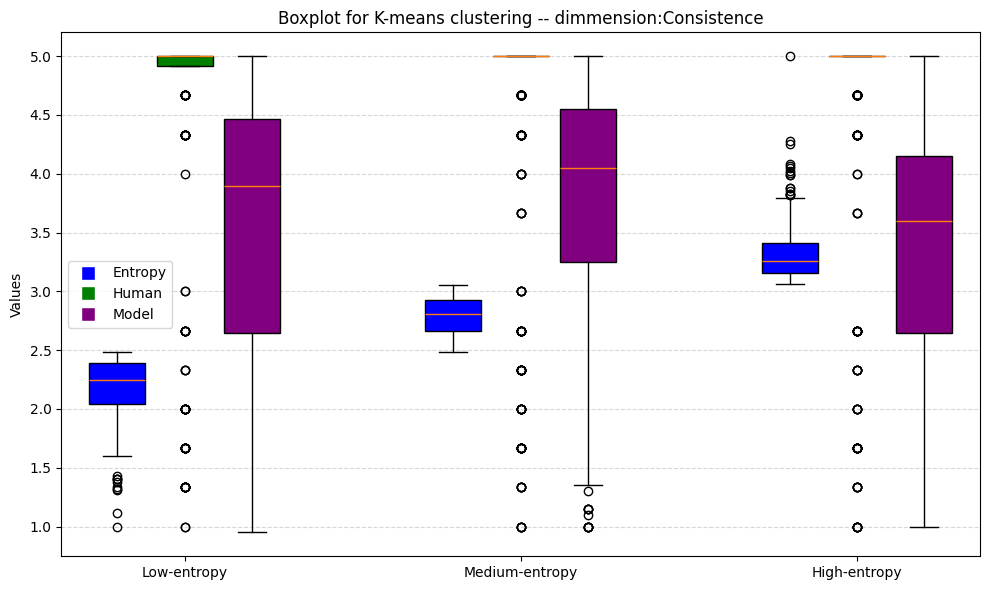

Cluster        r(Human)  p-value Sig r(Model)  p-value Sig 
------------------------------------------------------------------------
Low-entropy    0.34      1.47e-09***  0.40      7.98e-13***  
Medium-entropy 0.01      0.733        -0.02     0.57         
High-entropy   -0.01     0.896        -0.18     0.0001  ***  


In [137]:
dict1, dict2, dict3  =   e_scores_con_stand, h_scores_con, m_scores_con
boxplot_complexity(dict1,dict2,dict3,'Consistence',dict_label=['Entropy','Human','Model'],xticklabels=['Low-entropy','Medium-entropy','High-entropy'])

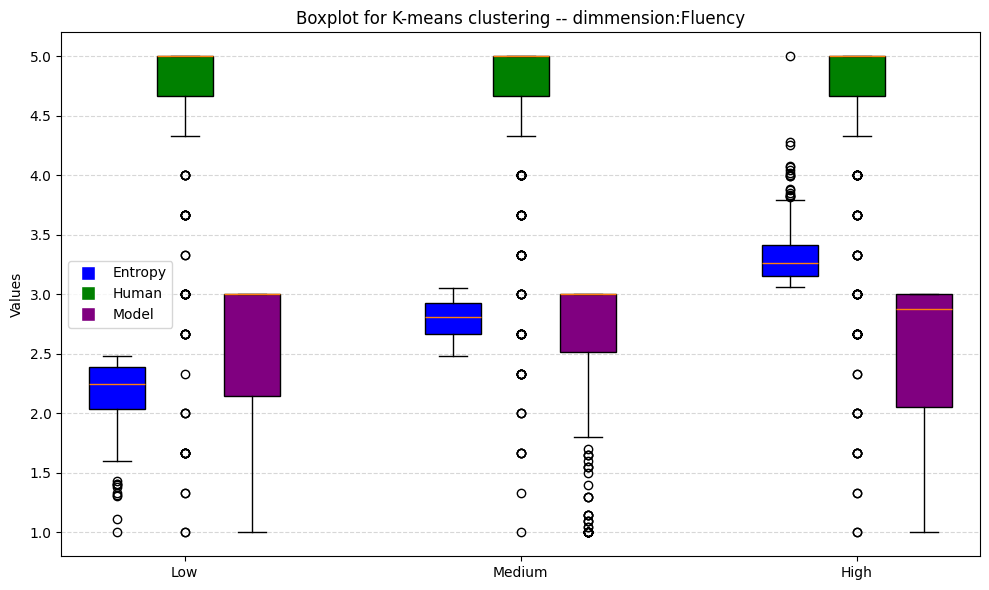

Cluster        r(Human)  p-value Sig r(Model)  p-value Sig 
------------------------------------------------------------------------
Low            0.49      2e-19   ***  0.37      4.5e-11 ***  
Medium         -0.07     0.0497  *    0.03      0.422        
High           -0.10     0.0229  *    -0.09     0.0517       


In [138]:
dict1, dict2, dict3  =   e_scores_flu_stand, h_scores_flu, m_scores_flu
boxplot_complexity(dict1,dict2,dict3,'Fluency',dict_label=['Entropy','Human','Model'],xticklabels=['Low','Medium','High'])

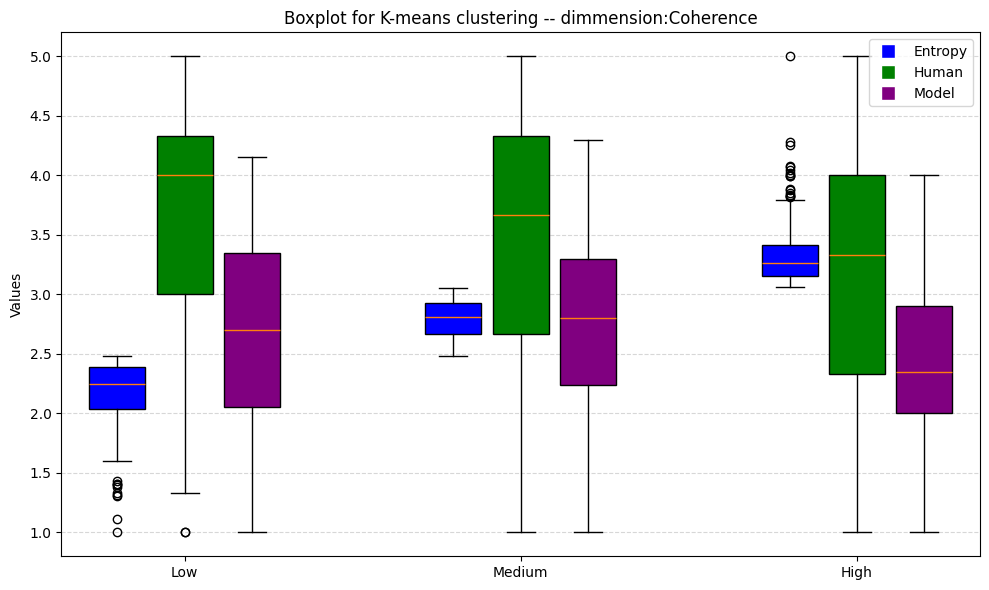

Cluster        r(Human)  p-value Sig r(Model)  p-value Sig 
------------------------------------------------------------------------
Low            0.24      2.68e-05***  0.27      1.38e-06***  
Medium         -0.00     0.89         -0.04     0.277        
High           -0.05     0.282        -0.21     2.45e-06***  


In [139]:
dict1, dict2, dict3  =   e_scores_coh_stand, h_scores_coh, m_scores_coh
boxplot_complexity(dict1,dict2,dict3,'Coherence',dict_label=['Entropy','Human','Model'],xticklabels=['Low','Medium','High'])

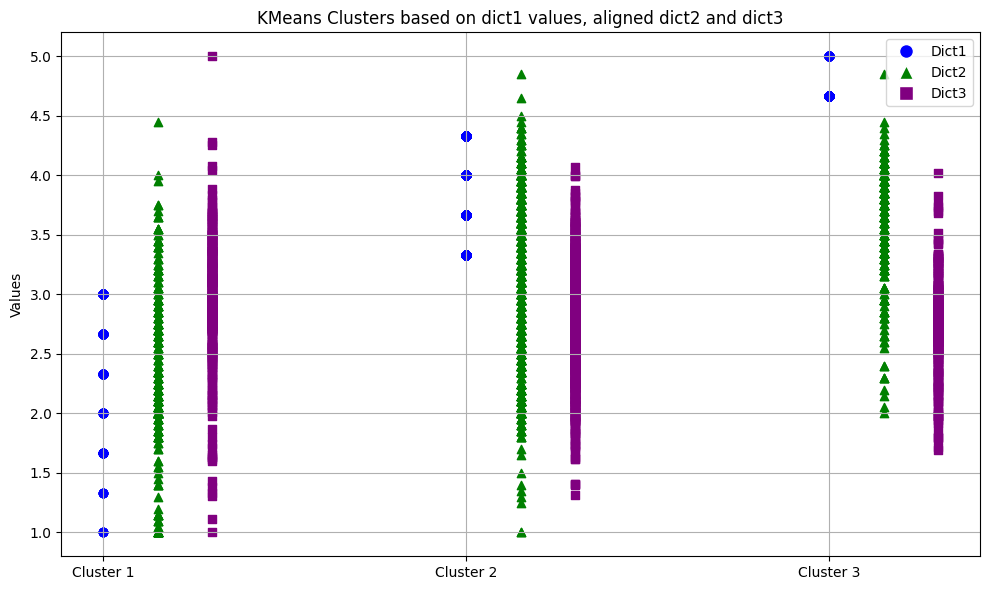

In [49]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from sklearn.cluster import KMeans
import numpy as np


# Flatten dict1 (key, index, value)
flattened1 = [(k, i, v) for k, lst in dict1.items() for i, v in enumerate(lst)]

# Create lookup dicts for dict2 and dict3
lookup2 = {(k, i): dict2[k][i] for k in dict2 for i in range(len(dict2[k]))}
lookup3 = {(k, i): dict3[k][i] for k in dict3 for i in range(len(dict3[k]))}

# Sort dict1 values by value
flattened1_sorted = sorted(flattened1, key=lambda x: x[2])

# Extract sorted dict1 values and aligned dict2, dict3 values
values1_sorted = np.array([v for (_, _, v) in flattened1_sorted]).reshape(-1, 1)
values2_aligned = [lookup2[(k, i)] for (k, i, _) in flattened1_sorted]
values3_aligned = [lookup3[(k, i)] for (k, i, _) in flattened1_sorted]

# Apply KMeans clustering on dict1 values
k = 3  # number of clusters
kmeans = KMeans(n_clusters=k, random_state=0)
clusters = kmeans.fit_predict(values1_sorted)  # cluster indices (0,1,2)

# We want clusters sorted by their cluster centers for consistent x-axis order
cluster_centers = kmeans.cluster_centers_.flatten()
sorted_clusters = np.argsort(cluster_centers)

# Map old cluster labels to sorted cluster order (0 = lowest cluster center)
cluster_map = {old: new for new, old in enumerate(sorted_clusters)}
mapped_clusters = np.array([cluster_map[c] for c in clusters])

# Prepare x positions for clusters
# Slightly offset for each dict, e.g., 1, 2, 3 for clusters
def get_x_positions(cluster_labels, offset):
    return [label + 1 + offset for label in cluster_labels]

x1 = get_x_positions(mapped_clusters, offset=0.0)   # dict1
x2 = get_x_positions(mapped_clusters, offset=0.15)  # dict2
x3 = get_x_positions(mapped_clusters, offset=0.3)   # dict3

plt.figure(figsize=(10,6))

# Define colors and markers for dicts
color1 = 'blue'
color2 = 'green'
color3 = 'purple'

# Plot dict1
plt.scatter(x1, values1_sorted.flatten(), color=color1, marker='o')

# Plot dict2
plt.scatter(x2, values2_aligned, color=color2, marker='^')

# Plot dict3
plt.scatter(x3, values3_aligned, color=color3, marker='s')

# Custom legend for dicts
legend_elements = [
    Line2D([0], [0], marker='o', color='w', label='Dict1', markerfacecolor=color1, markersize=10),
    Line2D([0], [0], marker='^', color='w', label='Dict2', markerfacecolor=color2, markersize=10),
    Line2D([0], [0], marker='s', color='w', label='Dict3', markerfacecolor=color3, markersize=10),
]

plt.xticks([1, 2, 3], ['Cluster 1', 'Cluster 2', 'Cluster 3'])
plt.ylabel('Values')
plt.title('KMeans Clusters based on dict1 values, aligned dict2 and dict3')
plt.legend(handles=legend_elements, loc='best')
plt.grid(True)
plt.tight_layout()
plt.show()


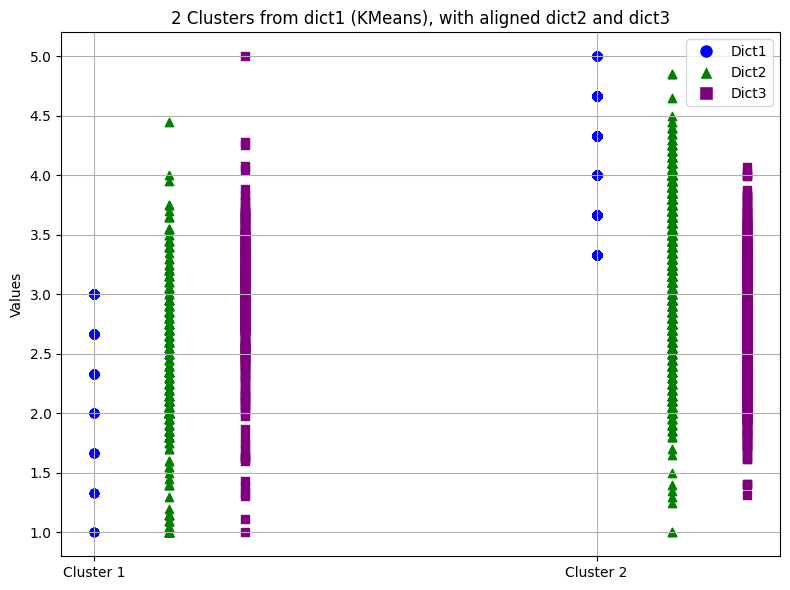

In [50]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from sklearn.cluster import KMeans
import numpy as np



# Flatten dict1 (key, index, value)
flattened1 = [(k, i, v) for k, lst in dict1.items() for i, v in enumerate(lst)]

# Create lookup dicts for dict2 and dict3
lookup2 = {(k, i): dict2[k][i] for k in dict2 for i in range(len(dict2[k]))}
lookup3 = {(k, i): dict3[k][i] for k in dict3 for i in range(len(dict3[k]))}

# Sort dict1 values by value
flattened1_sorted = sorted(flattened1, key=lambda x: x[2])

# Extract sorted dict1 values and aligned dict2, dict3 values
values1_sorted = np.array([v for (_, _, v) in flattened1_sorted]).reshape(-1, 1)
values2_aligned = [lookup2[(k, i)] for (k, i, _) in flattened1_sorted]
values3_aligned = [lookup3[(k, i)] for (k, i, _) in flattened1_sorted]

# KMeans clustering (2 clusters)
kmeans = KMeans(n_clusters=2, random_state=0)
clusters = kmeans.fit_predict(values1_sorted)

# Sort clusters by center (lowest = cluster 0)
cluster_centers = kmeans.cluster_centers_.flatten()
sorted_clusters = np.argsort(cluster_centers)
cluster_map = {old: new for new, old in enumerate(sorted_clusters)}
mapped_clusters = np.array([cluster_map[c] for c in clusters])

# Prepare x positions for clusters
def get_x_positions(cluster_labels, offset):
    return [label + 1 + offset for label in cluster_labels]

x1 = get_x_positions(mapped_clusters, offset=0.0)   # dict1
x2 = get_x_positions(mapped_clusters, offset=0.15)  # dict2
x3 = get_x_positions(mapped_clusters, offset=0.3)   # dict3

plt.figure(figsize=(8,6))

# Dict-specific colors and markers
color1, color2, color3 = 'blue', 'green', 'purple'

plt.scatter(x1, values1_sorted.flatten(), color=color1, marker='o')   # Dict1
plt.scatter(x2, values2_aligned, color=color2, marker='^')            # Dict2
plt.scatter(x3, values3_aligned, color=color3, marker='s')            # Dict3

# Custom legend
legend_elements = [
    Line2D([0], [0], marker='o', color='w', label='Dict1', markerfacecolor=color1, markersize=10),
    Line2D([0], [0], marker='^', color='w', label='Dict2', markerfacecolor=color2, markersize=10),
    Line2D([0], [0], marker='s', color='w', label='Dict3', markerfacecolor=color3, markersize=10),
]

plt.xticks([1, 2], ['Cluster 1', 'Cluster 2'])
plt.ylabel('Values')
plt.title('2 Clusters from dict1 (KMeans), with aligned dict2 and dict3')
plt.legend(handles=legend_elements, loc='best')
plt.grid(True)
plt.tight_layout()
plt.show()


In [17]:
# -------TEST--------

results = []


ent_vals, human_vals, model_vals = [], [], []

for doc_id in e_scores_rel:
    e_list = e_scores_rel.get(doc_id, [])
    h_list = h_scores_rel.get(doc_id, [])
    m_list = m_scores_rel.get(doc_id, [])

    if not (len(e_list) == len(h_list) == len(m_list)):
        continue

    for i in range(len(e_list)):
        ent_vals.append(e_list[i])
        human_vals.append(h_list[i])
        model_vals.append(m_list[i])

corr_h, pval_h = pearsonr(ent_vals, human_vals)
corr_m, pval_m = pearsonr(ent_vals, model_vals)
# import pdb; pdb.set_trace()
results.append(('rel', 'human', corr_h, pval_h))
results.append(('rel', 'model', corr_m, pval_m))

In [18]:
len(results)

2

In [19]:
len(e_list),len(e_scores_rel),len(ent_vals)

(16, 100, 1600)

In [20]:
len(m_list),len(m_scores_rel),len(model_vals)

(16, 100, 1600)

In [21]:
len(h_list),len(h_scores_rel),len(human_vals)

(16, 100, 1600)

In [26]:

def find_significant_entropy_correlations(
    model_scores, human_scores, en_scores, dim_name
):
    results_by_doc = []
    results_all_entity = []

    ent_vals, human_vals, model_vals = [], [], []

    for doc_id in en_scores:
        e_list = en_scores.get(doc_id, [])
        h_list = human_scores.get(doc_id, [])
        m_list = model_scores.get(doc_id, [])

        if not (len(e_list) == len(h_list) == len(m_list)):
            continue

        for i in range(len(e_list)):
            ent_vals.append(e_list[i])
            human_vals.append(h_list[i])
            model_vals.append(m_list[i])
       
    
        if len(ent_vals) < 2:
            continue  # skip if too little data for correlation
    
        # Compute correlations !!!! This is wrong! corr is computed using the already appended list of human_vals and model_vals !!!!
        # corr_h, pval_h = pearsonr(ent_vals, human_vals)
        # corr_m, pval_m = pearsonr(ent_vals, model_vals)
        # print('ent_val len', len(ent_vals))
        # print('h_val len', len(human_vals))

        # fix for the bug above
        corr_h, pval_h = pearsonr(e_list, h_list)
        corr_m, pval_m = pearsonr(e_list, h_list)

        # Collect significant ones
        # if pval_h < 0.05:
        #     results.append((dim_name, 'human', corr_h, pval_h))
        # if pval_m < 0.05:
        #     results.append((dim_name, 'model', corr_m, pval_m))

        # collect all 
        results_by_doc.append((dim_name, 'human', corr_h, pval_h))
        results_by_doc.append((dim_name, 'model', corr_m, pval_m))

    # Compute correlations 
    corr_h, pval_h = pearsonr(ent_vals, human_vals)
    corr_m, pval_m = pearsonr(ent_vals, model_vals)
    # collect all 
    results_all_entity.append((dim_name, 'human', corr_h, pval_h))
    results_all_entity.append((dim_name, 'model', corr_m, pval_m))

    # Print table
    print(f"Correlation for dimmension - {dim_name}") 
    table = PrettyTable()
    table.field_names = ["Score Type", "Correlation (r)", "P-value"]
    table.add_row(["Human Score", f"{corr_h:.3f}", f"{pval_h:.3g}"])
    table.add_row(["Model Score", f"{corr_m:.3f}", f"{pval_m:.3g}"])

    print(table)
    return results_by_doc,results_all_entity


In [47]:
res_rel100,res_rel1 = find_significant_entropy_correlations(m_scores_rel,h_scores_rel,e_scores_rel, 'relevance')
res_con100,res_con1 = find_significant_entropy_correlations(m_scores_con,h_scores_con,e_scores_con, 'consistency')
res_coh100,res_coh1 = find_significant_entropy_correlations(m_scores_coh,h_scores_coh,e_scores_coh, 'coherence')
res_flu100,res_flu1 = find_significant_entropy_correlations(m_scores_flu,h_scores_flu,e_scores_flu, 'fluency')

Correlation for dimmension - relevance
+-------------+-----------------+----------+
|  Score Type | Correlation (r) | P-value  |
+-------------+-----------------+----------+
| Human Score |      -0.170     | 8.46e-12 |
| Model Score |      -0.060     |  0.0157  |
+-------------+-----------------+----------+
Correlation for dimmension - consistency
+-------------+-----------------+----------+
|  Score Type | Correlation (r) | P-value  |
+-------------+-----------------+----------+
| Human Score |      0.112      | 6.97e-06 |
| Model Score |      -0.023     |   0.36   |
+-------------+-----------------+----------+
Correlation for dimmension - coherence
+-------------+-----------------+----------+
|  Score Type | Correlation (r) | P-value  |
+-------------+-----------------+----------+
| Human Score |      -0.139     | 2.39e-08 |
| Model Score |      -0.132     | 1.29e-07 |
+-------------+-----------------+----------+
Correlation for dimmension - fluency
+-------------+-----------------+-

/tmp/ipykernel_1870388/2113455389.py:33: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  corr_h, pval_h = pearsonr(e_list, h_list)
/tmp/ipykernel_1870388/2113455389.py:34: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  corr_m, pval_m = pearsonr(e_list, h_list)


In [ ]:
# We can observe low but significant correlations with human ratings. Negative cor in rel and coh dimmensions. This could be due to the fact that
# we're using GPT2 with has more uncertainities compared to GPT4. 
# LLM ratings are generated with GPT4. We can generate entropies with GPT4 and compare the results.

In [48]:
len(res_rel100),len(res_rel1)

(200, 2)

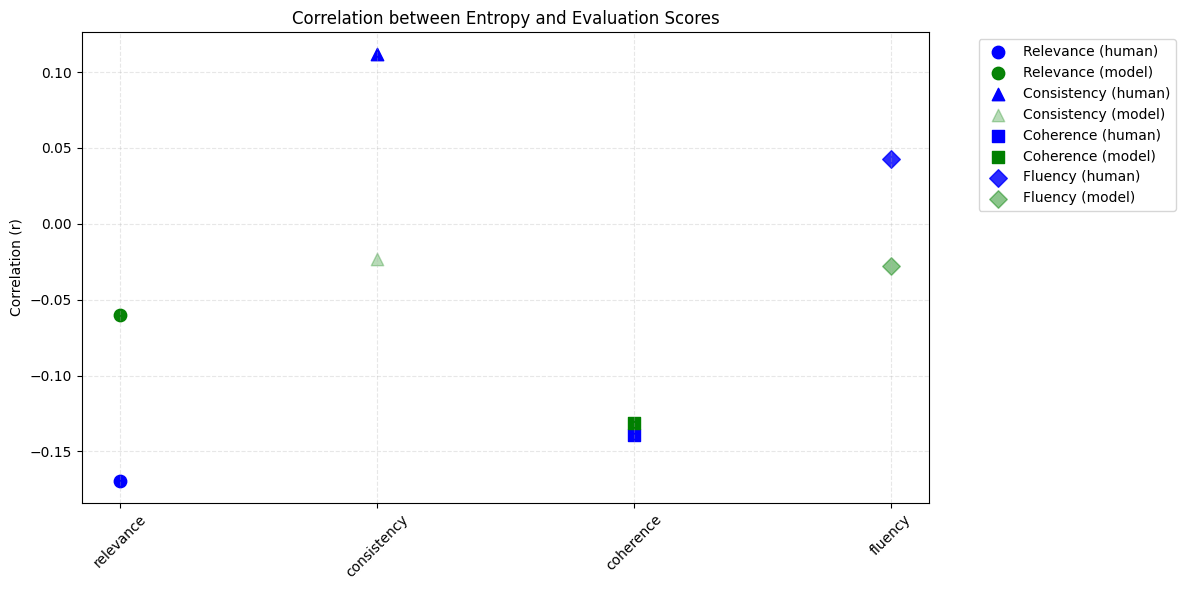

In [29]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Assuming these variables are defined earlier:
# res_rel1, res_con1, res_coh1, res_flu1 = find_significant_entropy_correlations(...)
# readability_metrics = ['relevance', 'consistency', 'coherence', 'fluency']

all_results = []
corrs = [res_rel1, res_con1, res_coh1, res_flu1]

dim_name_map = {'rel': 'relevance', 'con': 'consistency', 'coh': 'coherence', 'flu': 'fluency'}

for c in corrs:    
    for dim, score_type, corr, p in c:
        all_results.append({
            "dimension": dim_name_map[dim],  # convert here
            "score_type": score_type,
            "correlation": corr,
            "p_value": p
        })

# Convert to DataFrame
df = pd.DataFrame(all_results)

# Set up plot
plt.figure(figsize=(12, 6))
colors = {'human': 'blue', 'model': 'green'}
markers = {'relevance': 'o', 'coherence': 's', 'fluency': 'D', 'consistency': '^'}

# Define metric order on x-axis
readability_metrics = ['relevance', 'consistency', 'coherence', 'fluency']
metric_indices = {metric: i for i, metric in enumerate(readability_metrics)}

for idx, row in df.iterrows():
    x = metric_indices[row['dimension']]
    y = row['correlation']
    p = row['p_value']

    # Alpha scaled by p-value (lower p → more opaque)
    alpha = min(1.0, max(0.2, 1 - p * 2))
    
    plt.scatter(
        x, y,
        color=colors[row['score_type']],
        marker=markers[row['dimension']],
        s=80,
        alpha=alpha,
        label=f"{row['dimension'].title()} ({row['score_type']})"
    )

# Deduplicate legend
handles, labels = plt.gca().get_legend_handles_labels()
by_label = dict(zip(labels, handles))
plt.legend(by_label.values(), by_label.keys(), bbox_to_anchor=(1.05, 1), loc='upper left')

# Axis labels and formatting
plt.xticks(
    ticks=range(len(readability_metrics)),
    labels=[m.replace('_', '\n') for m in readability_metrics],
    rotation=45
)
plt.ylabel("Correlation (r)")
plt.title("Correlation between Entropy and Evaluation Scores")
plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
filename = os.path.join(saving_path, "all_correlations_entropy.png")
plt.savefig(filename, dpi=100)
plt.show()


In [ ]:
## add preplexity to the plot above

In [30]:
def flatten_dicts_list(dicts_list):
        return [
        [(k, v) for k, lst in d.items() for v in lst]
        for d in dicts_list
    ]

In [31]:
from scipy.stats import kendalltau
import matplotlib.pyplot as plt

def compute_kendall_tau(list1,list2):
    taus = []
    for row1, row2 in zip(list1, list2):
        v1 = [val for key, val in row1]
        v2 = [val for key, val in row2]
        if len(v1) == len(v2) and len(v1) >= 2:
            tau, _ = kendalltau(v1, v2)
            taus.append(tau)
        else:
            taus.append(None)
    return taus
   
def flatten_dicts(dict):
    # return [(k, v) for d in dicts for k, lst in d.items() for v in lst]
    return [(k, v) for k, lst in dict.items() for v in lst]

In [42]:
model_sum = [m_scores_coh,m_scores_flu]

human_sum = [h_scores_coh, h_scores_flu]

ent_sum = [e_scores_coh, e_scores_flu]



In [43]:
model_sum_flat = flatten_dicts_list(model_sum)
ent_sum_flat = flatten_dicts_list(ent_sum) 
tau_model_sum = compute_kendall_tau(model_sum_flat,ent_sum_flat)

In [44]:
human_sum_flat = flatten_dicts_list(human_sum)
ent_sum_flat = flatten_dicts_list(ent_sum)
tau_human_sum = compute_kendall_tau(human_sum_flat,ent_sum_flat)

In [45]:
tau_model_sum,tau_human_sum

([np.float64(-0.11772398466936608), np.float64(-0.08235228734004846)],
 [np.float64(-0.11643518084021115), np.float64(-0.06097645305737856)])

In [48]:
 # Print table
print(f"Kendall Tau for Coherence") 
table = PrettyTable()
table.field_names = ["Score Type", "Kendall Tau"]
table.add_row(["Human Score", f"{tau_human_sum[0]:.3f}"])
table.add_row(["Model Score", f"{tau_model_sum[0]:.3f}"])

print(table)

Kendall Tau for Coherence
+-------------+-------------+
|  Score Type | Kendall Tau |
+-------------+-------------+
| Human Score |    -0.116   |
| Model Score |    -0.118   |
+-------------+-------------+


In [46]:
 # Print table
print(f"Kendall Tau for Fluency") 
table = PrettyTable()
table.field_names = ["Score Type", "Kendall Tau"]
table.add_row(["Human Score", f"{tau_human_sum[1]:.3f}"])
table.add_row(["Model Score", f"{tau_model_sum[1]:.3f}"])

print(table)

Kendall Tau for Fluency
+-------------+-------------+
|  Score Type | Kendall Tau |
+-------------+-------------+
| Human Score |    -0.061   |
| Model Score |    -0.082   |
+-------------+-------------+


In [35]:


def plot_correlation_with_pvalue_errorbars(results,dim):
    # Convert to DataFrame
    df = pd.DataFrame(results, columns=["dimension", "source", "correlation", "p_value"])
    df["index"] = range(len(df))  # use list index as x-axis

    plt.figure(figsize=(10, 6))

    # Plot with error bars (p-value as the 'error')
    for source in df["source"].unique():
        sub_df = df[df["source"] == source]
        plt.errorbar(
            sub_df["index"],
            sub_df["correlation"],
            yerr=sub_df["p_value"],
            fmt='o',
            label=source,
            capsize=4
        )

    plt.axhline(0, color='gray', linestyle='--', linewidth=0.8)
    plt.title(f'Correlations with Entropy (P-Value - Error Bars) --{dim}')
    plt.xlabel("Result Index")
    plt.ylabel("Pearson Correlation (± p-value)")
    # plt.xticks(df["index"])
    plt.legend(title="Source")
    plt.tight_layout()
    plt.show()


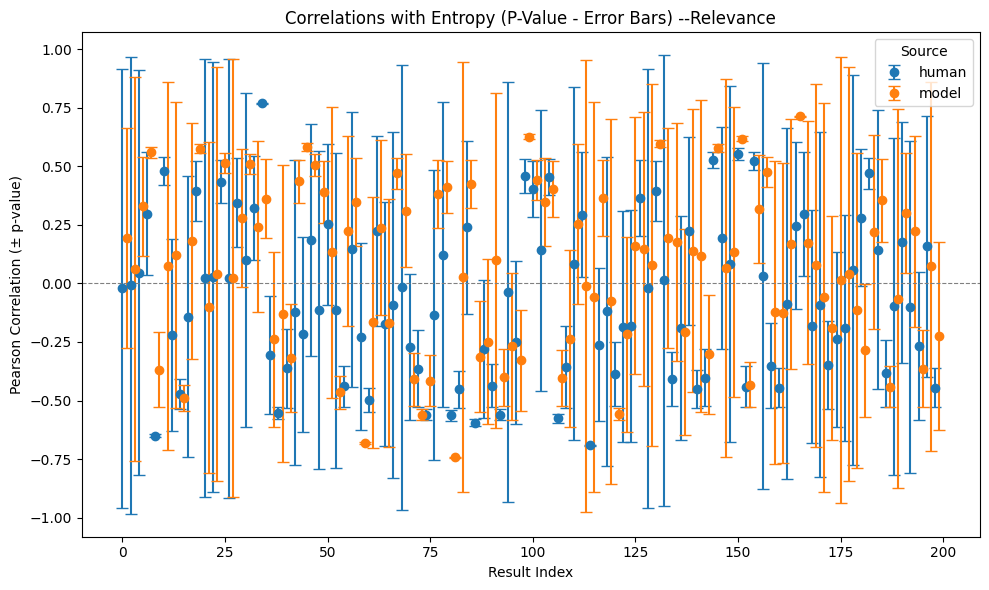

In [44]:
plot_correlation_with_pvalue_errorbars(res_rel100,'Relevance')

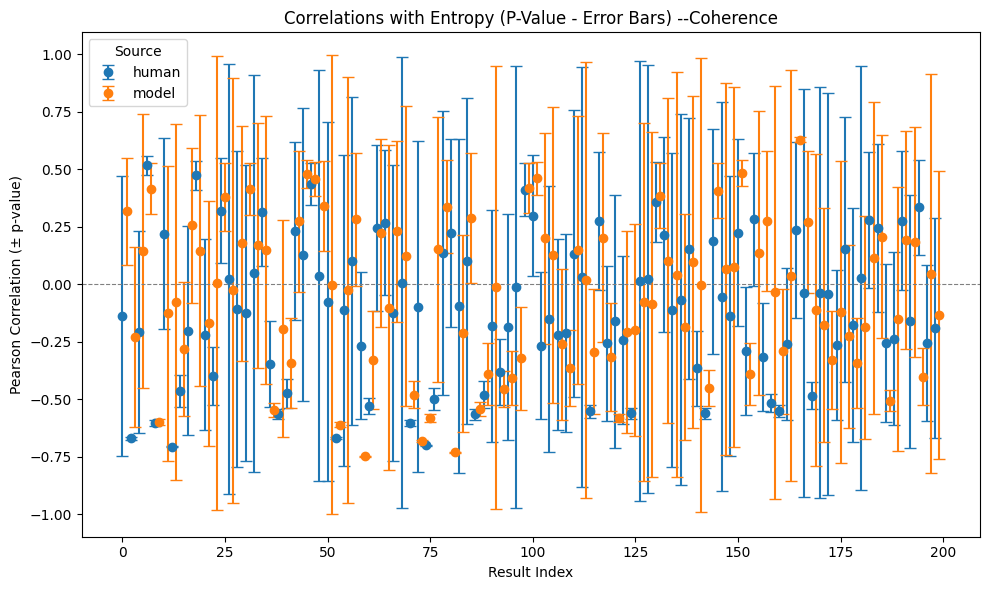

In [45]:
plot_correlation_with_pvalue_errorbars(res_coh100,'Coherence')

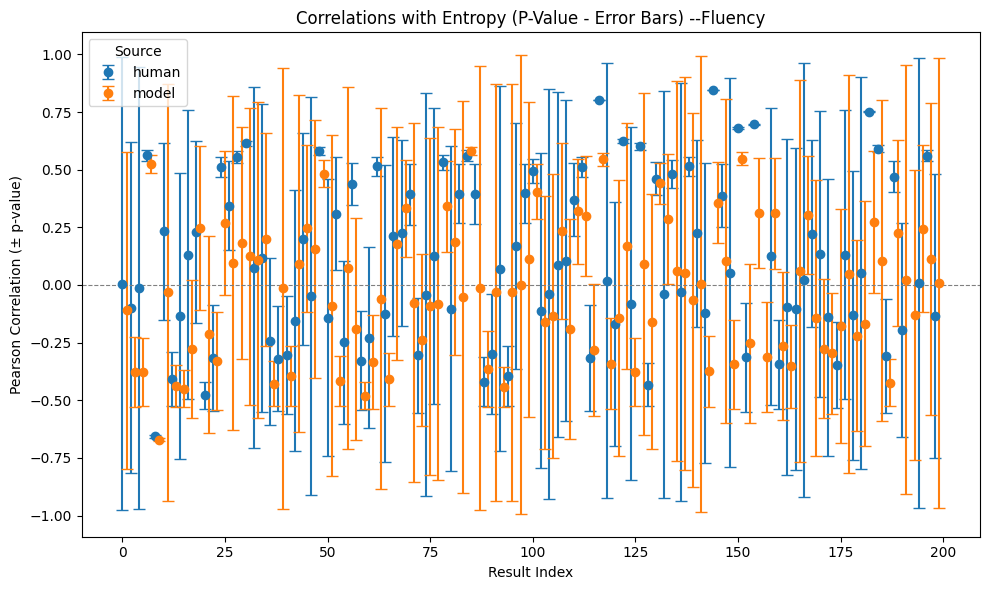

In [46]:
plot_correlation_with_pvalue_errorbars(res_flu100,'Fluency')

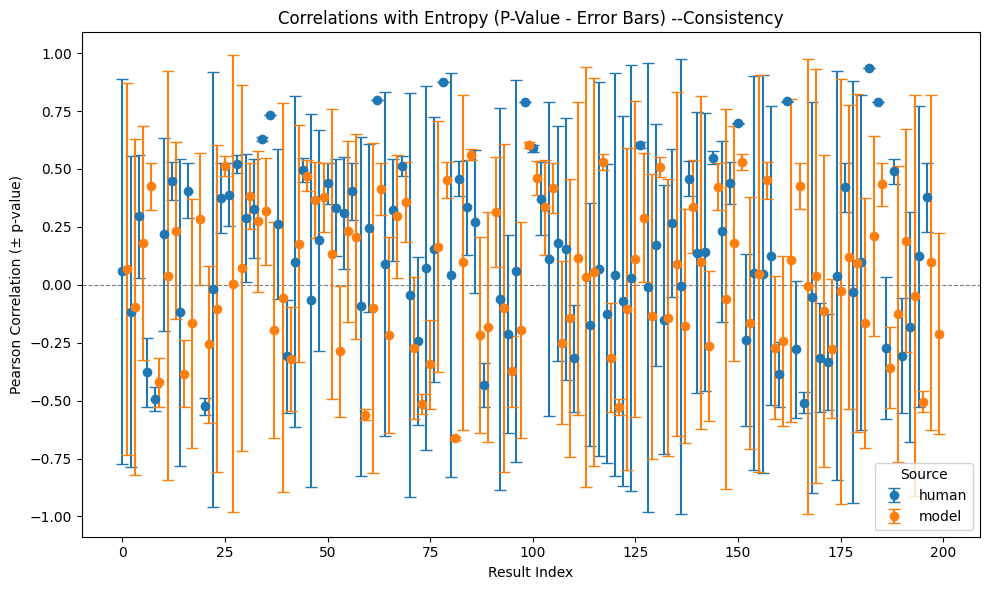

In [47]:
plot_correlation_with_pvalue_errorbars(res_con100,'Consistency')

In [131]:
res_rel1

[('rel',
  'human',
  np.float64(-0.16965654359961885),
  np.float64(8.460080538851425e-12)),
 ('rel',
  'model',
  np.float64(-0.06039890133499749),
  np.float64(0.01568025551562846))]

In [133]:
corrs

[[('rel',
   'human',
   np.float64(-0.16965654359961885),
   np.float64(8.460080538851425e-12)),
  ('rel',
   'model',
   np.float64(-0.06039890133499749),
   np.float64(0.01568025551562846))],
 [('con',
   'human',
   np.float64(0.1120949198771635),
   np.float64(6.9745420192818205e-06)),
  ('con',
   'model',
   np.float64(-0.02288595879435486),
   np.float64(0.36027420206757255))],
 [('coh',
   'human',
   np.float64(-0.1389557234866067),
   np.float64(2.391670220462432e-08)),
  ('coh',
   'model',
   np.float64(-0.13154573603043765),
   np.float64(1.2870578401138415e-07))],
 [('flu',
   'human',
   np.float64(0.04280121126284917),
   np.float64(0.0869898227853588)),
  ('flu',
   'model',
   np.float64(-0.02748487948516606),
   np.float64(0.2718799508075619))]]

In [137]:
import matplotlib.pyplot as plt
import numpy as np

# res_rel100,res_rel1 = find_significant_entropy_correlations(m_rel,h_rel,e_rel, 'rel')
# res_con100,res_con1 = find_significant_entropy_correlations(m_con,h_con,e_con, 'con')
# res_coh100,res_coh1 = find_significant_entropy_correlations(m_coh,h_coh,e_coh, 'coh')
# res_flu100,res_flu1 = find_significant_entropy_correlations(m_flu,h_flu,e_flu, 'flu')

all_results = []
corrs = [res_rel1,res_con1,res_coh1,res_flu1]
# significant = find_significant_readability_correlations(
#         model_scores_rel, human_scores_rel, red_scores_rel,
#         model_scores_coh, human_scores_coh, red_scores_coh,
#         model_scores_flu, human_scores_flu, red_scores_flu,
#         model_scores_con, human_scores_con, red_scores_con,
#         readability_measure = metric
#     )
for c in corrs:    
    for dim, score_type, corr, p in c:
        all_results.append({
            "dimension": dim,
            "score_type": score_type,
            "correlation": corr,
            "p_value": p
        })
    
    # Convert to structured arrays
import pandas as pd

df = pd.DataFrame(all_results)

# Set plot style
plt.figure(figsize=(12, 6))
colors = {'human': 'blue', 'model': 'green'}
markers = {'relevance': 'o', 'coherence': 's', 'fluency': 'D', 'consistency': '^'}

# Map metrics to x-locations
metric_indices = {metric: i for i, metric in enumerate(readability_metrics)}

for idx, row in df.iterrows():
    x = metric_indices[row['dimension']]
    y = row['correlation']
    p = row['p_value']

    # Optional: scale alpha based on p-value
    alpha = min(1.0, max(0.2, 1 - p * 2))  # Lower p -> more opaque
    plt.scatter(
        x, y,
        color=colors[row['score_type']],
        marker=markers[row['dimension']],
        s=80,
        alpha=alpha,
        label=f"{row['dimension'].title()} ({row['score_type']})"
    )

# Avoid duplicate legends
handles, labels = plt.gca().get_legend_handles_labels()
by_label = dict(zip(labels, handles))
plt.legend(by_label.values(), by_label.keys(), bbox_to_anchor=(1.05, 1), loc='upper left')

plt.xticks(ticks=range(len(readability_metrics)), labels=[m.replace('_', '\n') for m in row['dimmension']], rotation=45)
plt.ylabel("Correlation (r)")
plt.title("Correlation between Readability and Evaluation Scores")
plt.grid(True, linestyle='--', alpha=0.3)
# plt.legend()
plt.tight_layout()
plt.show()


SyntaxError: closing parenthesis ')' does not match opening parenthesis '[' (1941250214.py, line 61)

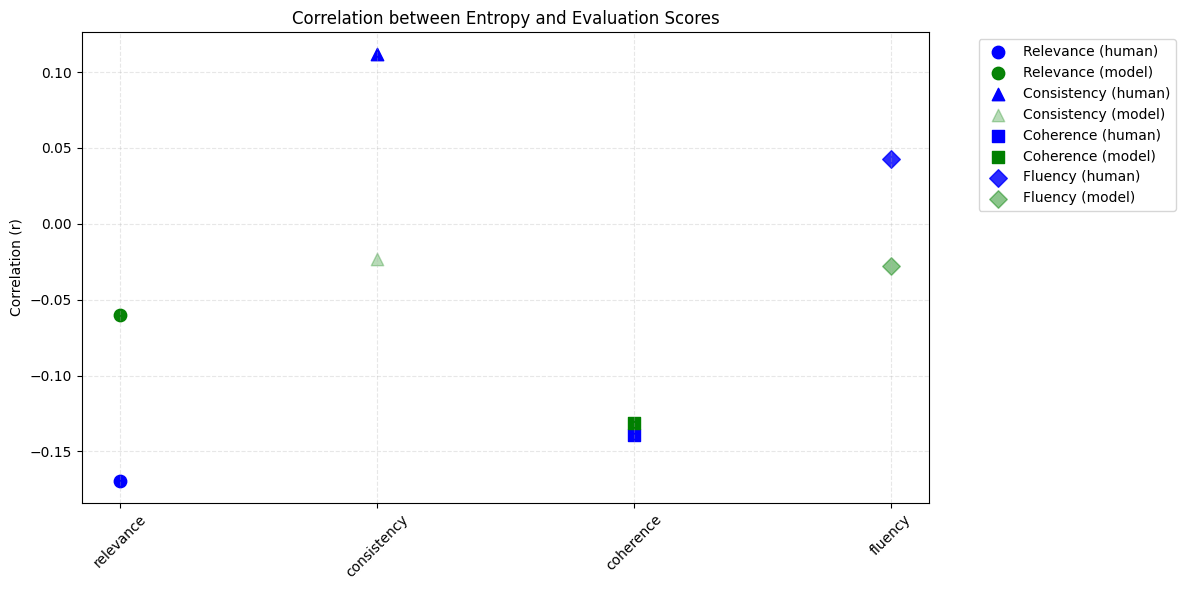